In [14]:
import numpy as np
import pandas as pd
from pathlib import Path


In [15]:
folder = Path("Data_file_awa")
classes = folder / Path("classes.txt")
classes

PosixPath('Data_file_awa/classes.txt')

In [ ]:

animals = []
num = []
with open(classes, "r", encoding="utf-8") as file:
    for line in file:
        # .strip() removes the trailing newline character (\n)
        striped = line.split()
        num.append(striped[0])
        animals.append(striped[1])
print(num)
print(animals)        
        

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50']
['antelope', 'grizzly+bear', 'killer+whale', 'beaver', 'dalmatian', 'persian+cat', 'horse', 'german+shepherd', 'blue+whale', 'siamese+cat', 'skunk', 'mole', 'tiger', 'hippopotamus', 'leopard', 'moose', 'spider+monkey', 'humpback+whale', 'elephant', 'gorilla', 'ox', 'fox', 'sheep', 'seal', 'chimpanzee', 'hamster', 'squirrel', 'rhinoceros', 'rabbit', 'bat', 'giraffe', 'wolf', 'chihuahua', 'rat', 'weasel', 'otter', 'buffalo', 'zebra', 'giant+panda', 'deer', 'bobcat', 'pig', 'lion', 'mouse', 'polar+bear', 'collie', 'walrus', 'raccoon', 'cow', 'dolphin']


In [22]:
matrix = folder / Path("predicate-matrix-continuous.txt")
mat = []
with open(matrix, 'r', encoding='utf-8') as file:
    for line in file:
        striped = line.split()
        mat.append(striped)

In [26]:
from scipy.cluster.hierarchy import dendrogram, linkage
from matplotlib import pyplot as plt

In [28]:
mat = np.array(mat, dtype=float)

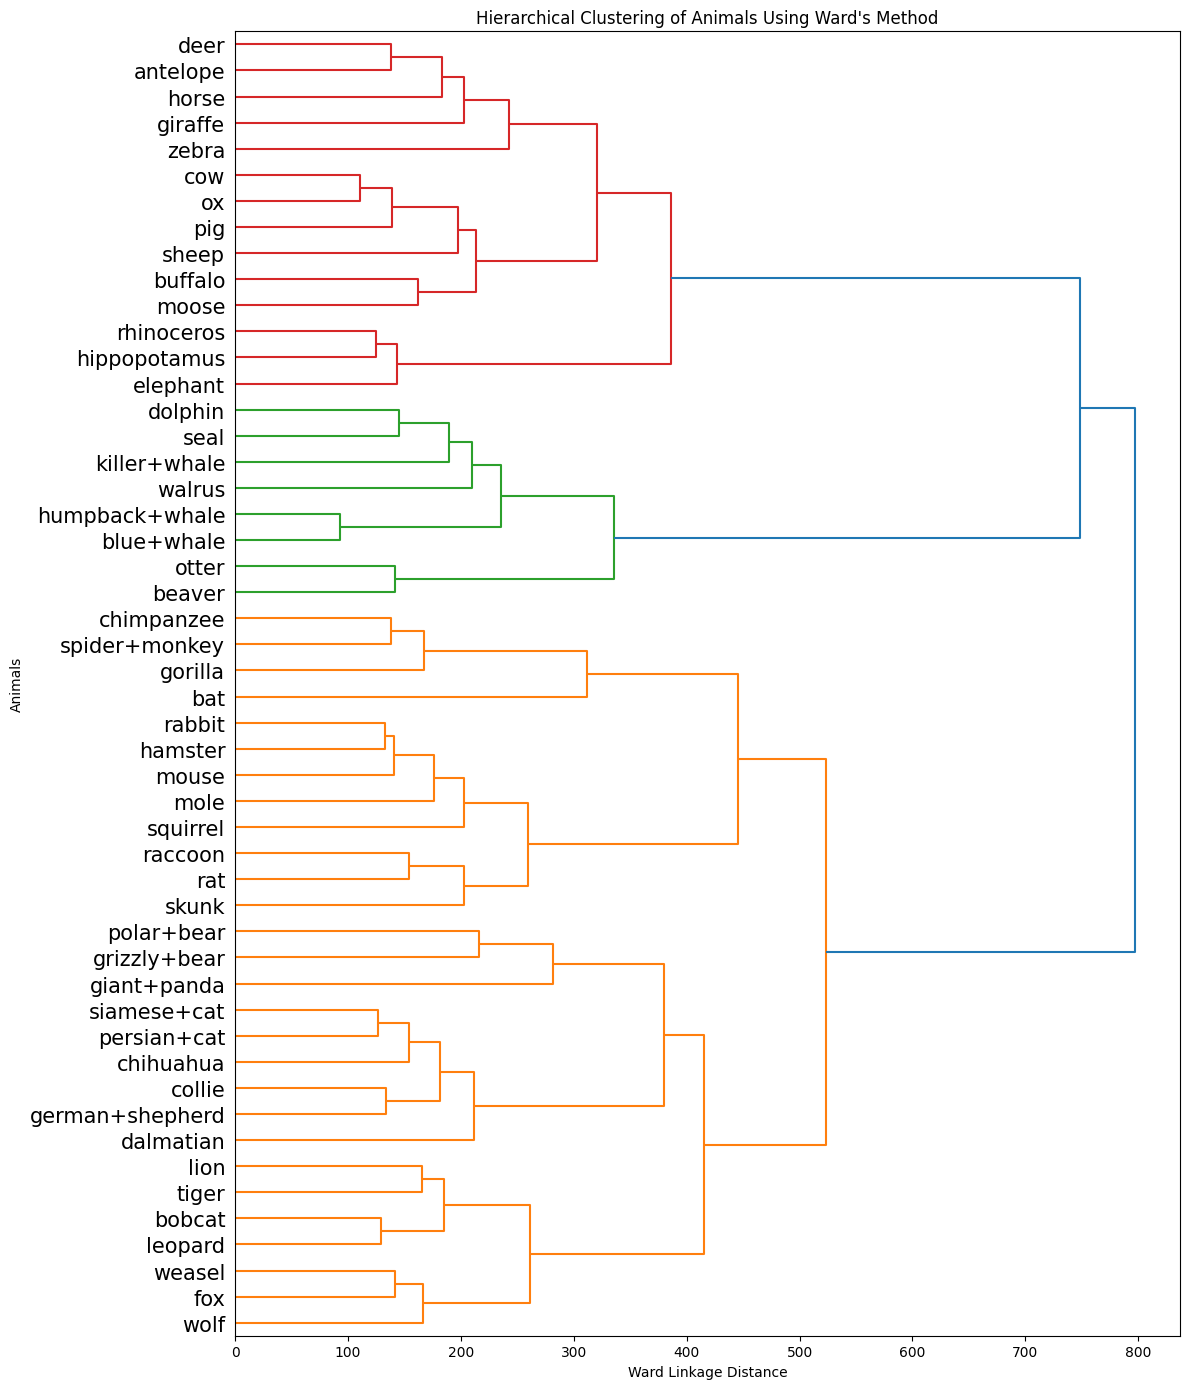

In [36]:
Z = linkage(mat, 'ward')
fig = plt.figure(figsize=(12, 14))
dn = dendrogram(Z, orientation = 'right', labels = animals, leaf_font_size=15)
plt.xlabel("Ward Linkage Distance")
plt.ylabel("Animals")
plt.title("Hierarchical Clustering of Animals Using Ward's Method")
plt.tight_layout()
plt.savefig("1a.png")

plt.show()

In [38]:
print(type(Z))

print(Z)


<class 'numpy.ndarray'>
[[  8.          17.          93.23886261   2.        ]
 [ 20.          48.         110.86784475   2.        ]
 [ 13.          27.         124.90353838   2.        ]
 [  5.           9.         126.38570449   2.        ]
 [ 14.          40.         129.12976225   2.        ]
 [ 25.          28.         132.71845802   2.        ]
 [  7.          45.         133.45206405   2.        ]
 [ 16.          24.         137.70507325   2.        ]
 [  0.          39.         137.82095378   2.        ]
 [ 41.          51.         138.88495215   3.        ]
 [ 43.          55.         140.90045174   3.        ]
 [  3.          35.         141.8782323    2.        ]
 [ 21.          34.         141.96461214   2.        ]
 [ 18.          52.         143.81295804   3.        ]
 [ 23.          49.         145.45584382   2.        ]
 [ 32.          53.         153.74801668   3.        ]
 [ 33.          47.         154.22537599   2.        ]
 [ 15.          36.         162.39138555 

In [40]:
Z[10: 3]

array([], shape=(0, 4), dtype=float64)

In [41]:
for i, (cluster1, cluster2, distance, size) in enumerate(Z):
    print(
        f"Step {i + 1}: "
        f"Merge {int(cluster1)} and {int(cluster2)} "
        f"-> Cluster {50 + i} | "
        f"Distance: {distance:.2f} | "
        f"Animals: {int(size)}"
    )
    

Step 1: Merge 8 and 17 -> Cluster 50 | Distance: 93.24 | Animals: 2
Step 2: Merge 20 and 48 -> Cluster 51 | Distance: 110.87 | Animals: 2
Step 3: Merge 13 and 27 -> Cluster 52 | Distance: 124.90 | Animals: 2
Step 4: Merge 5 and 9 -> Cluster 53 | Distance: 126.39 | Animals: 2
Step 5: Merge 14 and 40 -> Cluster 54 | Distance: 129.13 | Animals: 2
Step 6: Merge 25 and 28 -> Cluster 55 | Distance: 132.72 | Animals: 2
Step 7: Merge 7 and 45 -> Cluster 56 | Distance: 133.45 | Animals: 2
Step 8: Merge 16 and 24 -> Cluster 57 | Distance: 137.71 | Animals: 2
Step 9: Merge 0 and 39 -> Cluster 58 | Distance: 137.82 | Animals: 2
Step 10: Merge 41 and 51 -> Cluster 59 | Distance: 138.88 | Animals: 3
Step 11: Merge 43 and 55 -> Cluster 60 | Distance: 140.90 | Animals: 3
Step 12: Merge 3 and 35 -> Cluster 61 | Distance: 141.88 | Animals: 2
Step 13: Merge 21 and 34 -> Cluster 62 | Distance: 141.96 | Animals: 2
Step 14: Merge 18 and 52 -> Cluster 63 | Distance: 143.81 | Animals: 3
Step 15: Merge 23 and 

In [50]:
mat[1 == 1]

array([[[-1.  , -1.  , -1.  , ...,  2.35,  9.7 ,  8.38],
        [39.25,  1.39,  0.  , ..., 58.64, 20.14, 11.39],
        [83.4 , 64.79,  0.  , ..., 15.77, 13.41, 15.42],
        ...,
        [63.57, 43.1 ,  0.  , ..., 35.95, 28.26,  5.  ],
        [55.31, 55.46,  0.  , ...,  5.04, 18.89, 72.99],
        [10.22, 21.53, 27.73, ...,  3.96, 14.05, 37.98]]],
      shape=(1, 50, 85))

In [42]:
from scipy.cluster.hierarchy import cut_tree

Cluster 0: [0, 6, 30, 37, 39]
Cluster 1: [1, 38, 44]
Cluster 2: [2, 8, 17, 23, 46, 49]
Cluster 3: [3, 35]
Cluster 4: [4, 5, 7, 9, 32, 45]
Cluster 5: [10, 11, 25, 26, 28, 33, 43, 47]
Cluster 6: [12, 14, 21, 31, 34, 40, 42]
Cluster 7: [13, 18, 27]
Cluster 8: [15, 20, 22, 36, 41, 48]
Cluster 9: [16, 19, 24, 29]


In [44]:
ward_labels = cut_tree(Z, n_clusters=10).ravel()
ward_labels


array([0, 1, 2, 3, 4, 4, 0, 4, 2, 4, 5, 5, 6, 7, 6, 8, 9, 2, 7, 9, 8, 6,
       8, 2, 9, 5, 5, 7, 5, 9, 0, 6, 4, 5, 6, 3, 8, 0, 1, 0, 6, 8, 6, 5,
       1, 4, 2, 5, 8, 2])

In [ ]:
ward_cost = 0

for cluster_id in np.unique(ward_labels):
    
    cluster_points = mat[ward_labels == cluster_id]
    center = cluster_points.mean(axis=0)
    

    # Sum of squared L2 distances to the center
    ward_cost += np.sum((cluster_points - center) ** 2)
    
print("Ward's k-means cost:", ward_cost)

Ward's k-means cost: 679136.2672672619


In [63]:
np.unique(ward_labels)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [68]:
mat.shape

(50, 85)

In [70]:
mat[ward_labels == 2]

array([[83.4 , 64.79,  0.  ,  0.  ,  1.25,  0.  ,  0.  ,  0.  , 68.49,
        32.69,  0.  ,  1.25, 70.62, 57.04, 90.85,  1.25, 61.87, 22.68,
        79.94,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  1.25, 41.67, 12.5 ,
        45.15,  5.  , 30.22,  0.  ,  0.  ,  0.  ,  7.5 ,  1.25,  0.  ,
        91.45,  0.  ,  0.  , 57.37,  5.14, 63.35,  1.25, 10.45,  0.  ,
         0.  , 27.29, 13.23,  8.75,  0.  , 27.8 , 66.75, 21.81, 32.86,
         3.75,  0.  , 10.89,  0.  , 57.87,  6.61, 20.36, 15.  , 16.25,
        12.5 , 24.51, 30.11,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,
         0.  , 88.28,  0.  , 79.49,  0.  ,  0.  , 38.27,  9.77, 52.03,
        24.94, 15.77, 13.41, 15.42],
       [12.92,  4.38, 67.08,  7.5 , 25.6 ,  0.  ,  0.  ,  0.  , 15.31,
        23.75,  2.5 ,  0.  , 64.47, 45.17, 86.46,  0.  , 65.15, 11.88,
        64.87,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  , 26.42,  0.  ,
         0.  ,  0.  , 69.32,  0.  ,  0.  ,  0.  , 13.75,  0.  ,  0.  ,
        71.82,  0.  ,  0.  , 21.42, 42.6

In [ ]:
len(mat[ward_labels == 2]) # returns 85 feature data for every animal assigned to cluster 2.

6

In [61]:
for cluster_id in np.unique(ward_labels):
    indices = np.where(ward_labels == cluster_id)[0]
    cluster_points = mat[ward_labels == cluster_id]
    center = cluster_points.mean(axis=0)
    
    print(f"Center: {center}")
    
    print(f"Cluster {cluster_id}: {indices.tolist()}")

Center: [27.01  31.832  0.688 35.294 10.84   4.94   0.278  9.686 23.252 30.03
 19.772 36.914  7.754 24.718 55.436  5.844  9.156 47.606  0.     0.
 68.924  2.408  1.33  60.564 42.9   52.218 44.262  2.618 14.36   2.584
 37.558  0.     1.728 16.056  0.888  5.132  0.246  0.    63.034 65.796
  7.022 37.57   9.686 34.028  0.    74.606 42.774 13.122  0.97   1.61
 44.244  0.     5.382  0.    64.076  4.424 20.87  67.582  2.704  0.922
  0.     0.    32.744 61.63   1.458  1.554  4.226 25.164 50.774 20.956
 46.68   6.05  14.74   0.    63.426  0.444  1.976  0.246  5.422 48.146
 26.896 52.802  7.292 16.73  18.25 ]
Cluster 0: [0, 6, 30, 37, 39]
Center: [42.03333333 56.44666667  0.83333333 27.42        6.87666667  0.
  0.          0.83333333 28.73333333  8.05666667  0.         82.82
  0.         18.03666667 82.39666667  1.25       56.36666667  0.41666667
  0.         10.32        0.         23.87       68.73        4.87666667
  2.5         9.47       44.08333333 48.53       19.79        5.41666667
  0

In [72]:
mat.shape

(50, 85)

In [ ]:
from sklearn.cluster import KMeans
import random
import math

def get_center(X):
    animal = mat.shape[0]
    attr = mat.shape[1]
    
    # print(f"animal: {animal}")
    # print(f"attr: {attr}")
    
    animal = random.randint(0, (animal))
    attr = random.randint(0, (attr))

    
    return animal, attr
    
centers = []
smallest = float('inf')
range2 = 10
for i in range(range2):
    center1, center2 = get_center(mat)
    centers.append([center1, center2])
    
    k_mean = KMeans(n_clusters = 10, init = "random", max_iter= 10).fit(mat)
    
    if i % 100 == 0:
        print(f"{i}/{range2} Finished")
    i += 1

    if smallest > k_mean.inertia_:
    
        smallest = k_mean.inertia_
    
print(f"smallest K-mean: {smallest}")
    


0/10 Finished
smallest K-mean: 714213.531975119
